# RouteRanker – Module 5: Machine Learning Model Development and Evaluation
**Goal:** use the preprocessed data of Module 4 to (1) group routes with **clustering** (KMeans, DBSCAN) and (2) run **Random Forest / XGBoost** classification – and evaluate everything with the right metrics.

**Rules followed**
* A cluster is a group of routes with similar **scheduled** service – *not* a performance class and *not* an optimisation recommendation.
* GTFS has no passenger data, so **no label such as 'overcrowded' or 'underutilised' is created**. The only real label in the data is the **city** of a route, so the classifiers predict the city – a diagnostic of how comparable the feeds are, not a route-quality model.
* Classification uses separate training and validation data; every statistic was fitted on training routes only (Module 4).

In [1]:
import os, sys, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
from src import modeling as m
pd.set_option("display.max_columns", 40, "display.width", 200)
tr, va, feats = m.load_module4()
print("training routes:", len(tr), "| validation routes:", len(va), "| features:", len(feats))
print("cities:", tr.city.value_counts().to_dict())

training routes: 10466 | validation routes: 2600 | features: 25
cities: {'bengaluru': 3534, 'chennai': 3208, 'delhi': 2352, 'ahmedabad': 748, 'kochi': 379, 'pune': 245}


## 1. Understanding the algorithms (with tiny examples)
### K-Means – step by step
K-Means: choose K → place K centroids → assign every point to its nearest centroid → move each centroid to the mean of its points → repeat until nothing changes. Below the loop is written out by hand on 6 toy 'routes' (trips, stops) and compared with scikit-learn.

In [2]:
from sklearn.cluster import KMeans
toy = np.array([[2, 10], [3, 12], [2, 11], [20, 60], [22, 58], [21, 62]], dtype=float)    # (scheduled trips, stops)
def my_kmeans(X, centroids, steps=10):
    for step in range(steps):
        dist = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)     # distance of each point to each centroid
        labels = dist.argmin(axis=1)                                                # assign to the nearest centroid
        new = np.array([X[labels == k].mean(axis=0) for k in range(len(centroids))])   # recompute centroids
        print(f"step {step + 1}: labels = {labels}, centroids = {new.round(1).tolist()}")
        if np.allclose(new, centroids): break
        centroids = new
    return labels, centroids
labels, cents = my_kmeans(toy, toy[[0, 3]].copy())
sk = KMeans(2, n_init=10, random_state=0).fit(toy)
print("scikit-learn labels:", sk.labels_, "| same grouping:", len(set(zip(labels, sk.labels_))) == 2)

step 1: labels = [0 0 0 1 1 1], centroids = [[2.3, 11.0], [21.0, 60.0]]
step 2: labels = [0 0 0 1 1 1], centroids = [[2.3, 11.0], [21.0, 60.0]]
scikit-learn labels: [1 1 1 0 0 0] | same grouping: True


The loop stops when the centroids no longer move – the clusters are *stable*. scikit-learn does the same, with several random starts (`n_init`) to avoid a bad starting position.

### DBSCAN – core, border and noise points
`eps` = neighbourhood radius, `min_samples` = points needed within `eps` for a **core point**. Border points are within `eps` of a core point but not core themselves; points that are neither are **noise** (-1).

In [3]:
from sklearn.cluster import DBSCAN
pts = np.array([[1, 1], [1.2, 1], [1, 1.3], [1.1, 1.1], [5, 5], [5.2, 5], [5, 5.2], [5.3, 5.1], [3, 3.2], [9, 9]])
db = DBSCAN(eps=0.5, min_samples=3).fit(pts)
kind = np.where(db.labels_ == -1, "noise", np.where(np.isin(np.arange(len(pts)), db.core_sample_indices_), "core", "border"))
pd.DataFrame({"x": pts[:, 0], "y": pts[:, 1], "cluster": db.labels_, "type": kind})

,x,y,cluster,type
0,1.0,1.0,0,core
1,1.2,1.0,0,core
2,1.0,1.3,0,core
3,1.1,1.1,0,core
4,5.0,5.0,1,core
5,5.2,5.0,1,core
6,5.0,5.2,1,core
7,5.3,5.1,1,core
8,3.0,3.2,-1,noise
9,9.0,9.0,-1,noise


Two dense groups became clusters 0 and 1; the isolated points are noise. **Noise does not mean 'wrong'** – it only means the point is not in a dense region.

### Random Forest vs XGBoost
* **Random Forest:** many decision trees, each trained independently on a random sample of routes and features; the final class is the **majority vote**. Hard to over-fit, good first model.
* **XGBoost:** trees are built **one after another**; each new tree concentrates on the mistakes of the previous ones. More tuning options, often a bit more accurate.

A decision tree is a sequence of yes/no questions on the features (for example 'more than 40 stops?'); a leaf gives the class.

In [4]:
votes = {"Tree 1": "High", "Tree 2": "High", "Tree 3": "Low", "Tree 4": "High", "Tree 5": "Low"}
from collections import Counter
print(votes, "->", Counter(votes.values()).most_common(1)[0][0], "(majority vote, like a Random Forest)")

{'Tree 1': 'High', 'Tree 2': 'High', 'Tree 3': 'Low', 'Tree 4': 'High', 'Tree 5': 'Low'} -> High (majority vote, like a Random Forest)


## 2. Run the whole Module 5 pipeline
The runner fits and evaluates everything and writes models, figures, tables and reports (a few minutes). Settings are fixed by seeds, so reruns give the same results.

In [5]:
import run_module5
t0 = time.time(); run_module5.main(); print("seconds:", round(time.time() - t0))

done | KMeans K=7 sil 0.181/0.180 | DBSCAN eps=3.0 ms=10 clusters=4 noise 1.0%/1.0% | Random Forest (all features) acc 0.965 f1 0.948 | XGBoost (all features) acc 0.972 f1 0.961 | Random Forest (without length_method flags) acc 0.906 f1 0.911 | XGBoost (without length_method flags) acc 0.928 f1 0.932
seconds: 105


## 3. K-Means clustering
### Choosing K: elbow, silhouette and Davies-Bouldin

,k,inertia,silhouette,davies_bouldin,smallest_cluster_share
0,2,148096.366,0.161,1.947,0.369
1,3,129587.860,0.159,1.984,0.238
2,4,120256.563,0.159,1.864,0.132
3,5,112653.005,0.154,1.942,0.122
4,6,105741.157,0.172,1.680,0.082
5,7,100755.683,0.181,1.655,0.032
6,8,96146.860,0.153,1.764,0.031
7,9,91915.624,0.161,1.680,0.031
8,10,88279.303,0.161,1.699,0.032


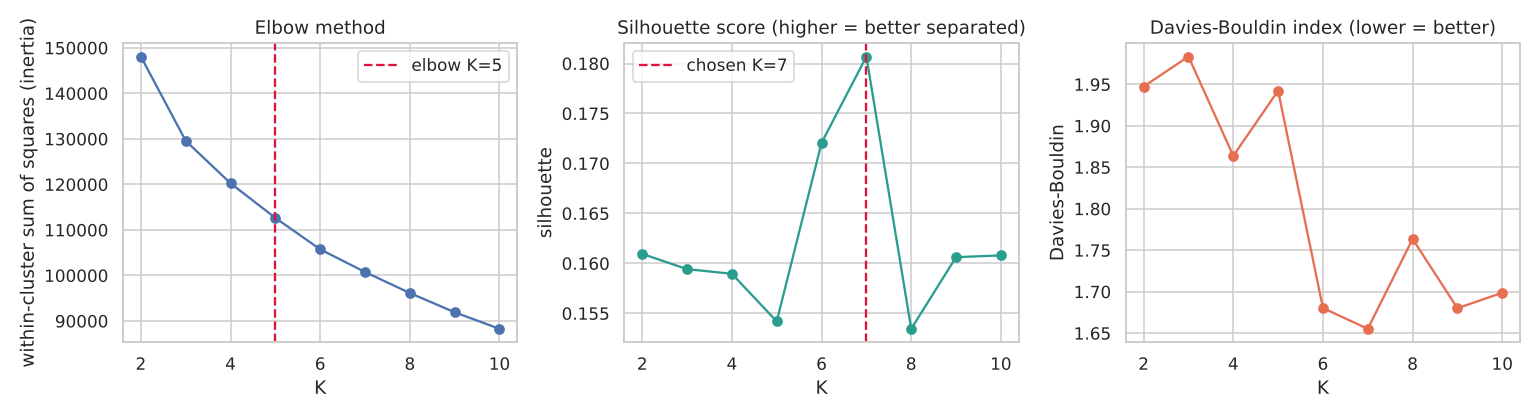

In [6]:
sweep = pd.read_csv("reports/tables/module5_kmeans_k_sweep.csv"); display(sweep.round(3))
display(Image("reports/figures/module5/m5_01_kmeans_k_selection.png"))

* **Elbow method:** inertia (within-cluster variation) always falls as K grows; the elbow is where the fall slows down.
* **Silhouette score** (−1 … +1): close to +1 = routes sit well inside their cluster and far from others; around 0 = clusters overlap.
* **Davies-Bouldin index:** lower = more compact and better separated.

Silhouette stays low for every K, i.e. scheduled service varies along a continuum rather than in clearly separate groups. The chosen K (best silhouette for K = 3–8, no cluster smaller than 2%) is therefore a convenient partition, not a sharp optimum.

K = 7


silhouette   train 0.181 | validation 0.180
Davies-Bouldin train 1.66 | validation 1.66


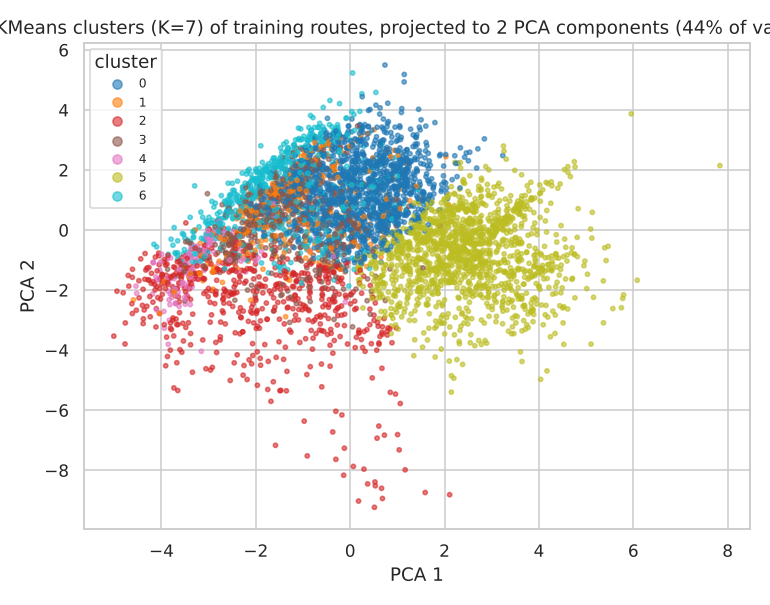

In [7]:
km = __import__("joblib").load("models/kmeans_model.joblib")
lab_tr, lab_va = km.labels_, km.predict(va[feats].values)
from sklearn.metrics import silhouette_score, davies_bouldin_score
print("K =", km.n_clusters)
print("silhouette   train %.3f | validation %.3f" % (silhouette_score(tr[feats].values, lab_tr, sample_size=6000, random_state=42), silhouette_score(va[feats].values, lab_va)))
print("Davies-Bouldin train %.2f | validation %.2f" % (davies_bouldin_score(tr[feats].values, lab_tr), davies_bouldin_score(va[feats].values, lab_va)))
display(Image("reports/figures/module5/m5_02_kmeans_pca_clusters.png"))

Train and validation scores are almost the same, so the clusters also hold for routes the model has not seen. The picture shows 25 features squeezed into 2 dimensions, so overlapping dots can still differ in other features.

,cluster,n_trips,n_unique_stops,length_km,service_span_h,trips_per_active_hour,median_headway_min,avg_speed_kmh,max_stop_overlap,mean_routes_per_stop,share_morning,share_afternoon,share_evening,routes
0,0,5.0,48.0,24.99,11.58,1.00,122.5,19.28,0.76,70.53,0.50,0.25,0.25,2918
1,1,2.0,28.0,17.17,0.75,1.00,35.0,17.82,0.67,57.39,0.00,0.00,1.00,645
2,2,6.0,9.0,4.03,9.33,1.33,37.5,16.57,0.50,44.67,0.41,0.20,0.00,1211
3,3,2.0,25.0,15.81,1.33,1.00,55.0,19.16,0.69,61.13,0.00,0.82,0.00,1129
4,4,2.0,2.0,10.79,8.33,1.00,498.0,16.35,0.33,8.00,0.50,0.50,0.00,334
5,5,34.0,45.0,21.89,15.33,2.20,24.0,15.03,0.64,50.02,0.41,0.30,0.24,2971
6,6,1.0,31.0,19.27,0.00,1.00,40.0,19.11,0.68,69.55,1.00,0.00,0.00,1258


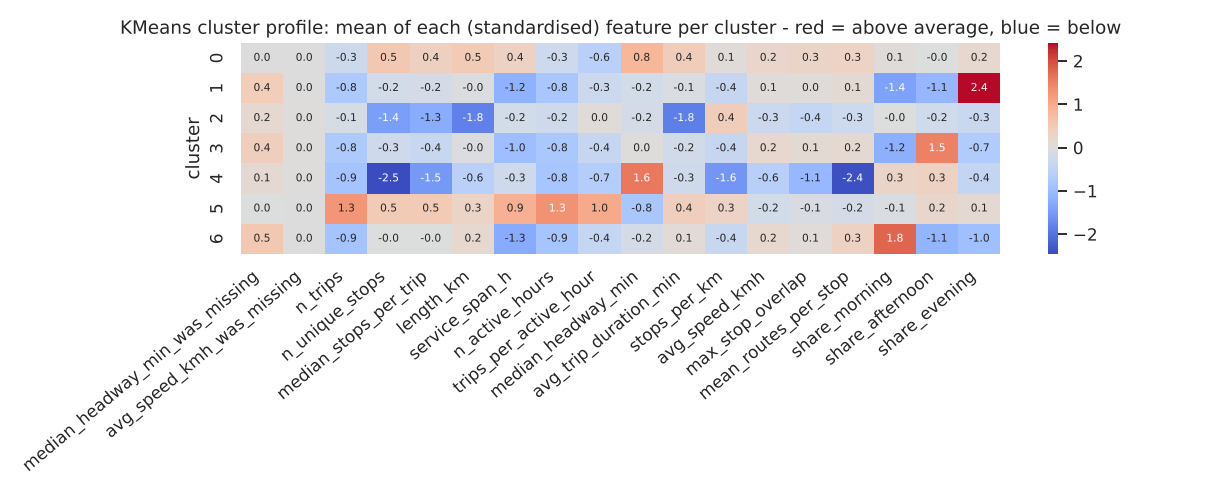

In [8]:
prof = pd.read_csv("reports/tables/module5_kmeans_cluster_profile.csv"); display(prof)
display(Image("reports/figures/module5/m5_04_kmeans_profile_heatmap.png"))

**How to read the clusters** – the table shows the median of each feature per cluster (original units). Several clusters are defined by *when* the route runs (only morning, only afternoon, only evening trips), others by single-trip routes or very short routes. These are patterns in the **timetable**; none of them says that a route is good, bad, crowded or empty.

,0,1,2,3,4,5,6
city,,,,,,,
ahmedabad,0.067,0.122,0.062,0.074,0.000,0.078,0.065
bengaluru,0.459,0.274,0.256,0.367,0.871,0.145,0.455
chennai,0.315,0.395,0.523,0.436,0.117,0.165,0.302
delhi,0.137,0.208,0.126,0.124,0.009,0.444,0.161
kochi,0.001,0.000,0.008,0.000,0.000,0.123,0.000
pune,0.020,0.000,0.026,0.000,0.003,0.045,0.016


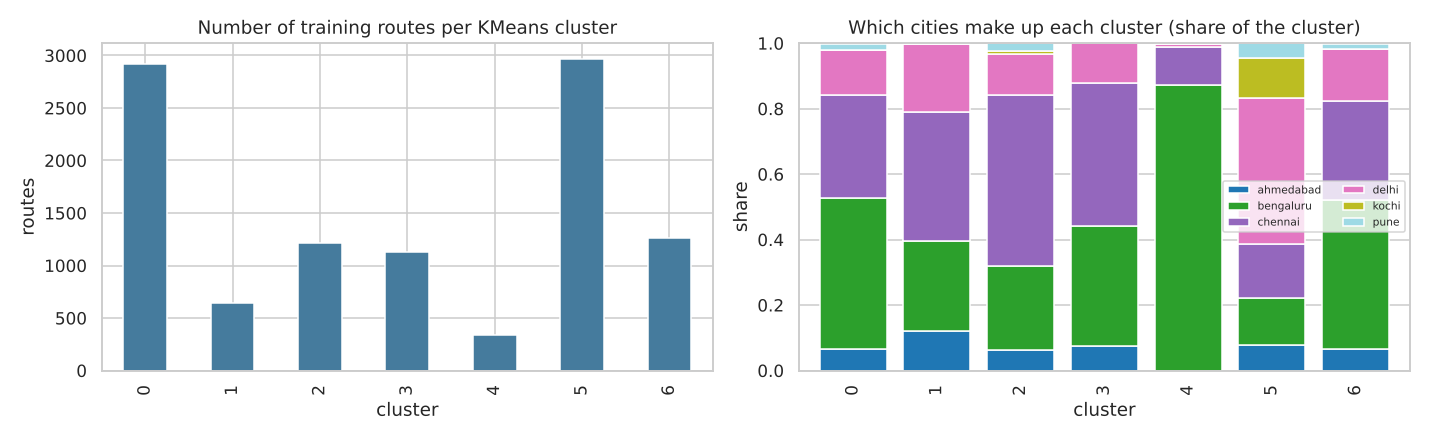

In [9]:
display(pd.read_csv("reports/tables/module5_kmeans_city_composition.csv", index_col=0))
display(Image("reports/figures/module5/m5_03_kmeans_sizes_and_cities.png"))

Some clusters are dominated by one city (for example a cluster that is mostly Bengaluru): they reflect how a feed is written as much as a service pattern – see the classification diagnostic below.

## 4. DBSCAN clustering
### Experiments with `eps` and `min_samples`

,eps,min_samples,clusters,noise_pct,largest_cluster_share,silhouette_non_noise
0,0.8,5,93,80.5,0.032,0.173
1,1.0,5,90,63.2,0.105,0.036
2,1.3,5,73,38.0,0.204,-0.096
3,1.6,5,46,20.2,0.680,-0.308
4,2.0,5,11,7.1,0.906,-0.001
5,2.5,5,7,1.9,0.975,0.154
6,3.0,5,1,0.7,0.993,NaN
7,0.8,10,23,91.1,0.023,0.371
8,1.0,10,36,75.8,0.066,0.222
9,1.3,10,31,49.7,0.168,0.094


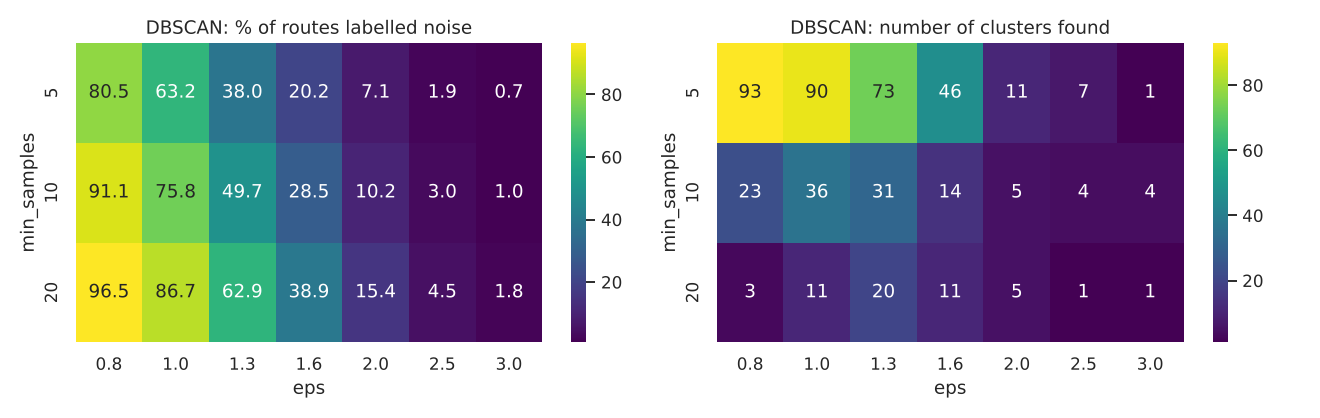

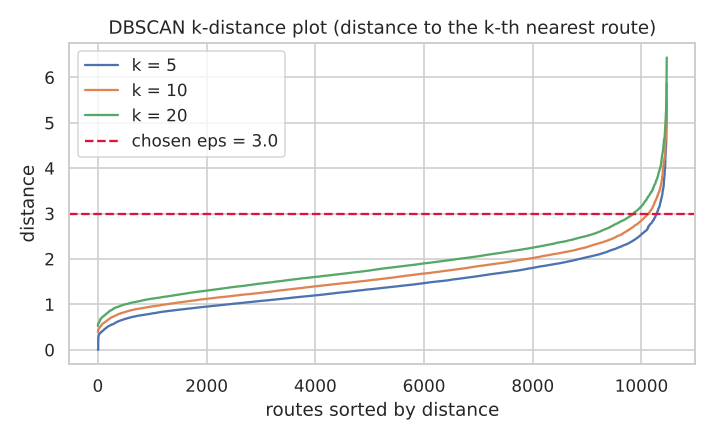

In [10]:
grid = pd.read_csv("reports/tables/module5_dbscan_parameter_grid.csv"); display(grid.round(3))
display(Image("reports/figures/module5/m5_06_dbscan_parameter_grid.png"))
display(Image("reports/figures/module5/m5_05_dbscan_kdistance.png"))

Small `eps` labels most routes as noise (many tiny clusters); large `eps` merges nearly everything into one cluster. The k-distance plot shows the distance scale of the data.

In [11]:
db = __import__("joblib").load("models/dbscan_model.joblib")
dl_tr, dl_va = db.labels_, m.dbscan_assign(db, va[feats].values)
print("eps =", db.eps, "| min_samples =", db.min_samples)
print("clusters:", len(set(dl_tr[dl_tr >= 0])), "| sizes:", np.bincount(dl_tr[dl_tr >= 0]).tolist())
print("noise  train %.1f%% | validation %.1f%%" % (100 * (dl_tr == -1).mean(), 100 * (dl_va == -1).mean()))

eps = 3.0 | min_samples = 10
clusters: 4 | sizes: [10311, 16, 20, 16]
noise  train 1.0% | validation 1.0%


DBSCAN finds one very large dense region plus a few small groups, so it is **not** a good segmentation here; its value is **finding unusual routes**.

,noise routes (median),other routes (median)
n_trips,4.00,6.00
n_unique_stops,5.00,36.00
length_km,4.92,19.26
service_span_h,8.08,10.42
trips_per_active_hour,1.58,1.00
median_headway_min,20.00,52.50
avg_speed_kmh,13.86,17.90
max_stop_overlap,0.44,0.67
mean_routes_per_stop,17.70,56.82
share_morning,0.35,0.43


city,ahmedabad,bengaluru,chennai,delhi,pune
noise_routes,11,97,15,4,3


,split,city,route_id,route_name,kmeans,n_trips,n_unique_stops,length_km,service_span_h,trips_per_active_hour,median_headway_min,avg_speed_kmh,max_stop_overlap,mean_routes_per_stop,share_morning,share_afternoon,share_evening
31,train,bengaluru,5838,JNSVS-4,4,2,2,0.041136,8.083333,1.000000,485.0,NaN,1.000000,4.000000,0.500000,0.500000,0.000000
26,train,bengaluru,5440,JNSVS-6,4,2,2,0.041136,8.416667,1.000000,505.0,NaN,1.000000,4.000000,0.500000,0.500000,0.000000
28,train,bengaluru,5578,JNSVS-5,2,4,2,0.041136,8.333333,1.333333,10.0,NaN,0.000000,4.000000,0.500000,0.500000,0.000000
110,validation,bengaluru,6430,JNSVS-1,4,2,2,0.041136,8.250000,1.000000,495.0,NaN,1.000000,4.000000,0.500000,0.500000,0.000000
54,train,bengaluru,8695,D20-D20G,2,4,3,0.041234,15.233333,1.000000,334.0,NaN,0.250000,3.333333,0.500000,0.250000,0.000000
66,train,bengaluru,9166,D19-D19G,2,4,2,0.071518,11.983333,1.333333,109.0,NaN,0.333333,7.000000,0.500000,0.000000,0.500000
47,train,bengaluru,7808,D22-D22G,2,35,2,0.078466,14.983333,2.916667,17.5,NaN,0.250000,3.500000,0.400000,0.314286,0.228571
114,validation,bengaluru,8015,D09-D09G,2,31,2,0.085794,15.483333,2.384615,20.0,NaN,0.333333,6.000000,0.387097,0.419355,0.161290


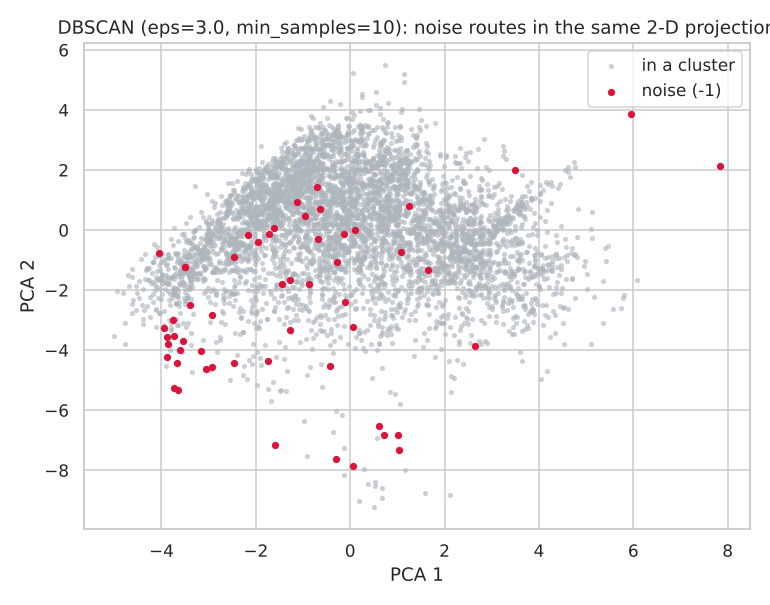

In [12]:
noise = pd.read_csv("reports/tables/module5_dbscan_noise_routes.csv")
display(pd.read_csv("reports/tables/module5_dbscan_noise_vs_other.csv", index_col=0))
display(noise.groupby("city").size().to_frame("noise_routes").T)
display(noise.sort_values("length_km").head(8))
display(Image("reports/figures/module5/m5_07_dbscan_noise_pca.png"))

### Noise-point analysis
Noise routes are mostly short routes with few stops that touch few other routes. **Noise is not an error:** each of these routes should be checked – is it (a) a data problem (many have no valid scheduled speed), (b) a special service, or (c) a rare but normal combination of values? All noise routes are listed in `reports/tables/module5_dbscan_noise_routes.csv`.

## 5. Classification: Random Forest and XGBoost
**Why the city?** Classification needs labels; GTFS has no passenger or performance labels and creating them would be an assumption. The city is a real, observed label. If routes of different cities are easy to tell apart from their scheduled-service features, the feeds have their own 'signature' and are not directly comparable. *This is a diagnostic and says nothing about route quality.*

Setup: Module-4 training/validation split (variants of one bus line stay on the same side), class weights for the imbalance (macro-F1 treats every city equally), hyper-parameters chosen by 3-fold grouped cross-validation on training routes only, validation used once.

In [13]:
res = pd.read_csv("reports/tables/module5_classification_results.csv"); display(res)
print("majority-class baseline accuracy:", round(np.bincount(pd.factorize(va.city)[0]).max() / len(va), 3))

,variant,model,best_params,cv_macro_f1,accuracy,precision_macro,recall_macro,f1_macro
0,all features,Random Forest,"{'n_estimators': 200, 'max_depth': 16, 'min_sa...",0.955,0.965,0.972,0.932,0.948
1,all features,XGBoost,"{'n_estimators': 200, 'max_depth': 4, 'learnin...",0.959,0.972,0.967,0.955,0.961
2,without length_method flags,Random Forest,"{'n_estimators': 200, 'max_depth': None, 'min_...",0.921,0.906,0.939,0.893,0.911
3,without length_method flags,XGBoost,"{'n_estimators': 200, 'max_depth': 6, 'learnin...",0.936,0.928,0.935,0.931,0.932


majority-class baseline accuracy: 0.339


**Metrics.** *Accuracy* = correct / all. *Precision* = of the routes predicted for a city, how many really belong to it. *Recall* = of the routes of a city, how many were found. *F1* = balance of precision and recall (macro = average over cities). The *confusion matrix* shows which cities get mixed up.

,class,precision,recall,f1,support
0,ahmedabad,0.885,0.826,0.855,224
1,bengaluru,0.997,1.000,0.998,882
2,chennai,0.947,0.961,0.954,726
3,delhi,0.990,0.997,0.993,612
4,kochi,1.000,0.988,0.994,86
5,pune,0.985,0.957,0.971,70


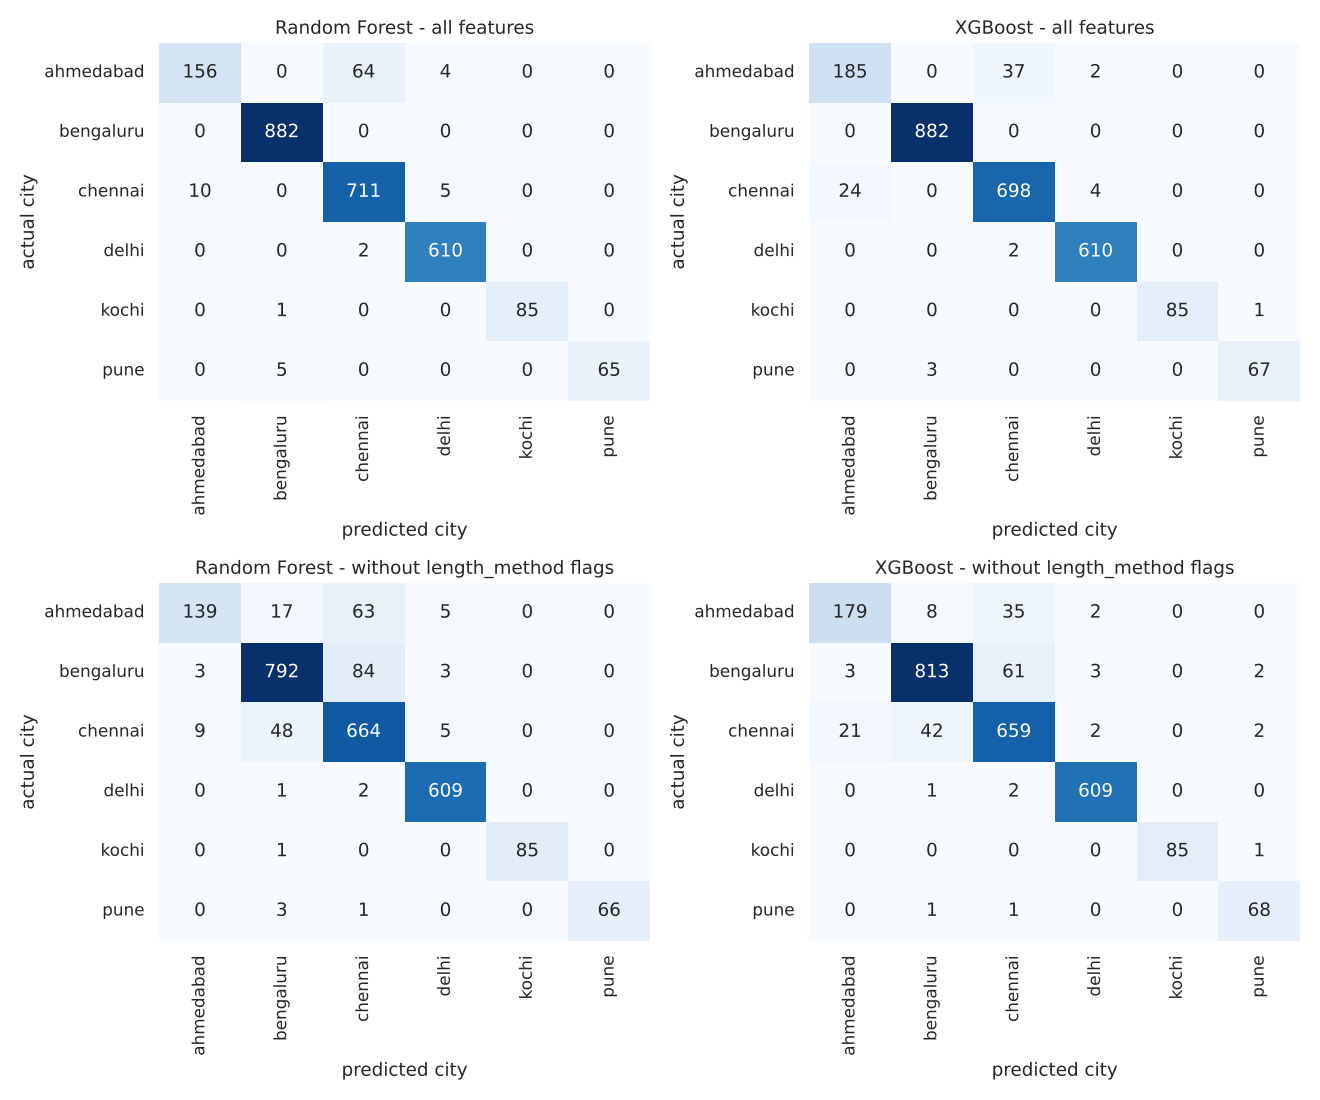

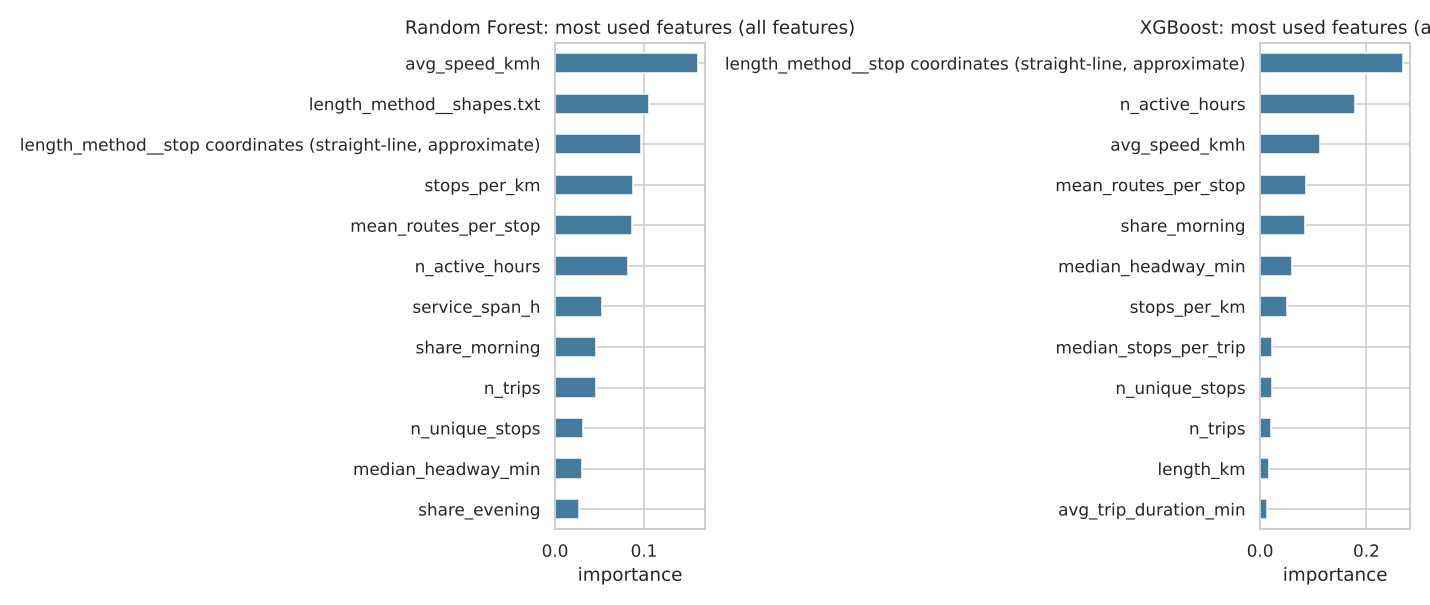

In [14]:
display(pd.read_csv("reports/tables/module5_classification_per_class_all_XGB.csv"))
display(Image("reports/figures/module5/m5_08_confusion_matrices.png"))
display(Image("reports/figures/module5/m5_09_feature_importance.png"))

**Reading:** both models separate the cities far better than the majority baseline, and still do well after removing the `length_method` flags, so the cities differ in how their schedules are written. A high score here is **not** a sign of a good route model. Practical consequence: compare routes *within* a feed, and do not compare raw trip counts across cities.

## 6. Comparison, observations and possible planning use

In [15]:
txt = open("reports/module5_comparison_and_suggestions.md", encoding="utf-8").read()
display(Markdown(txt[txt.index("## Comparison"):txt.index("## Limitations")]))

## Comparison

| algorithm | type | result | noise | silhouette (train / validation) | Davies-Bouldin (train / validation) | role in this project |
|---|---|---|---|---|---|---|
| KMeans | unsupervised | 7 clusters | 0% (every route assigned) | 0.18 / 0.18 | 1.66 / 1.66 | Gives a complete grouping of routes by scheduled-service pattern; needs K; clusters are weakly separated |
| DBSCAN | unsupervised | 4 clusters | 1.0% noise (train), 1.0% (validation) | 0.30 (non-noise) | 0.99 (non-noise) | Finds unusual routes; one dominant dense region, so weak as a segmentation |


*DBSCAN's silhouette is computed on the non-noise routes only and nearly all of them sit in one large cluster, so its higher value is **not** evidence that DBSCAN groups routes better than KMeans.*


| variant | model | accuracy | precision_macro | recall_macro | f1_macro |
|---|---|---|---|---|---|
| all features | Random Forest | 0.96 | 0.97 | 0.93 | 0.95 |
| all features | XGBoost | 0.97 | 0.97 | 0.95 | 0.96 |
| without length_method flags | Random Forest | 0.91 | 0.94 | 0.89 | 0.91 |
| without length_method flags | XGBoost | 0.93 | 0.94 | 0.93 | 0.93 |


*Clustering and classification cannot be compared with each other: clustering has no ground truth (internal measures only), classification was run on a different, real label (the city).* Random Forest and XGBoost: see the classification report; both separate the cities well, with XGBoost slightly better on macro F1 with all features.

## Main observations

1. The training routes do **not** form clearly separated groups (silhouette 0.15-0.18 for every K); scheduled service varies along a continuum, so any K is a convenient partition rather than a natural one.
2. The largest KMeans clusters hold 2,971 routes (cluster 5), 2,918 routes (cluster 0), 1,258 routes (cluster 6).
3. DBSCAN marks about 1% of routes as noise; these unusual routes are the most useful DBSCAN output.
4. The cities can be told apart from schedule features alone (classification diagnostic), so clusters partly reflect how each feed is written.
5. No cluster, noise flag or classifier output says anything about passengers, crowding or efficiency.

## Possible uses for route planning (candidates to investigate, not recommendations)

A cluster is not an optimisation recommendation. The groups below tell planners **where to look first**; ridership data and operator knowledge are needed before any change.

* **Review the noise routes first** (130 routes, `tables/module5_dbscan_noise_routes.csv`): check whether each is a data problem, a special service or a genuinely unusual route.
* **Very sparse service groups:** KMeans clusters 1, 3, 4, 6 have a median of at most 2 scheduled trips (3,366 routes). With ridership data, planners could check whether these are variants that could be consolidated with a main route or are intentional limited services.
* **High shared-stop groups:** clusters 0, 3 have the highest stop overlap with other routes; corridors served by many similar routes are candidates for timetable coordination studies - again only after checking passenger flows.
* **Compare within, not across, feeds:** use clusters per city, because the feeds are not directly comparable.



## 7. Limitations
* Scheduled data only – no ridership, occupancy, capacity or delays. Clusters and noise flags are **not** evidence of overcrowding, underutilisation or inefficiency.
* Weak cluster separation: results depend on K, `eps` and `min_samples` and are exploratory.
* DBSCAN has no native `predict`; validation routes were assigned through their nearest core point within `eps`.
* The classifiers predict the city, not a transport-planning quantity. Small classes (Pune, Kochi) have few validation routes.
* Several feeds are community-made or old; Hyderabad was excluded in Module 4.

**Next module:** turn model outputs into route-planning suggestions and integrate the project – once the mentor confirms what real ridership or performance data can be used.